In [56]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
df = pd.read_csv('netflix_titles.csv')

# A1. Dataset understanding



In [57]:
df.head()
df.tail()
df.shape
df.info()
df.columns
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


the file has 8,807 rows and 12 columns, which matches the standard Kaggle version exactly (no difference to report).
Only release_year is numeric; every other column is read as object (text), including date_added and duration, which will need fixing.

one title (a single Movie or TV Show) available in the Netflix catalogue.


# A2. Data Quality Assessment
## A2.1 Missing values


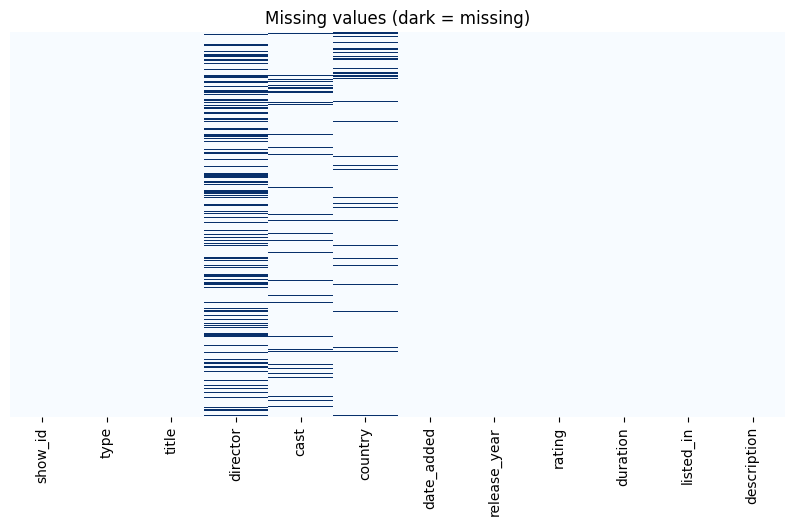

type
TV Show    2446
Movie       188
Name: count, dtype: int64

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [58]:
missing_values = df.isnull().sum()
missing_values[missing_values>0]
(df.isnull().sum() / len(df) * 100).round(2)
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), yticklabels = False, cbar = False, cmap="Blues")
plt.title('Missing values (dark = missing)')
plt.show()

print(df[df['director'].isnull()]['type'].value_counts())
print()
print(df['type'].value_counts())

## A2.2 Duplicate records


In [99]:
print("full-row duplicates:", df.duplicated().sum())
print("fuplicate show_id:", df['show_id'].duplicated().sum())
print("fuplicate title+type+year:", df.duplicated(subset=['title','type','release_year']).sum())

full-row duplicates: 0
fuplicate show_id: 0
fuplicate title+type+year: 0


## A2.3 Incorrect data types

In [60]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


## A2.4 Inconsistent categorical values

In [61]:
df['type'].value_counts()
df['rating'].value_counts()
# whitespace problems
c = df['country'].dropna()
d = df['date_added'].dropna()
print("country with extra spaces:", (c != c.str.strip()).sum())
print("country starting/ending with a comma:", (c.str.startswith(',') | c.str.endswith(',')).sum())
print("date_added with extra spaces:", (d != d.str.strip()).sum())

country with extra spaces: 0
country starting/ending with a comma: 7
date_added with extra spaces: 88


## A2.5 Suspicious or invalid values

In [100]:
df[df['rating'].str.contains('min', na=False)][['title','type','rating','duration']]
pd.crosstab(df['type'], df['duration'].str.contains('min', na=False))
temp_year_added = pd.to_datetime(df['date_added'].str.strip()).dt.year
print("Added before release year:", (temp_year_added < df['release_year']).sum())
df[temp_year_added < df['release_year']][['title','release_year','date_added']].head()

Added before release year: 14


,title,release_year,date_added
1551,Hilda,2021,"December 14, 2020"
1696,Polly Pocket,2021,"November 15, 2020"
2920,Love Is Blind,2021,"February 13, 2020"
3168,Fuller House,2020,"December 6, 2019"
3287,Maradona in Mexico,2020,"November 13, 2019"


## A2.6 Outliers

In [101]:
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR
print("LB:", lower_bound, "UB:", upper_bound)
outliers_year = df[(df['release_year'] < lower_bound) | (df['release_year'] > upper_bound)]
print("number of release_year outliers:", len(outliers_year))

movie_temp = df[df['type']=='Movie']['duration'].str.split(' ').str[0].astype(float)
Q1 = movie_temp.quantile(0.25)
Q3 = movie_temp.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR
print("LB:", lower_bound, "UB:", upper_bound)
print("num of movie-length outliers:", ((movie_temp < lower_bound) | (movie_temp > upper_bound)).sum())

LB: 2004.0 UB: 2028.0
number of release_year outliers: 719
LB: 46.5 UB: 154.5
num of movie-length outliers: 450


**A2.1**
Columns with missing values: director 2,634 (29.9%), country 831 (9.4%), cast 825 (9.4%), date_added 10 (0.11%), rating 4 (0.05%), duration 3 (0.03%). Of the 2,634 missing directors, 2,446 (92.9%) are TV Shows, although TV Shows are only 30% of the catalogue.

missing director is not random: TV Shows usually have no single credited director. So the missingness is *meaningful*, not just a data-entry accident. The tiny gaps in date_added, rating and duration look like genuine data-entry omissions.

**A2.2**
none found: 0 full-row duplicates, 0 duplicate `show_id`, 0 duplicate title+type+release_year. `show_id` is a valid unique key, so no rows need to be dropped.

**A2.3**
date_added is stored as text (should be a date). duration is text (should be a number once split into minutes / seasons). release_year is correctly an integer.

**A2.4**
**Observation:**
- type is clean (only Movie and TV Show).
- rating contains three values that are not ratings at all (74 mi, 84 mi`, 66 min). They are durations shifted into the wrong column.
- NR (80 titles) and UR (3 titles) both mean "not rated" (overlapping labels).
- 88 date_added values have leading spaces, and 7 country cells start or end with a stray comma.

**A2.5**
3 rows (all Louis C.K. stand-up specials) have the rating/duration shift, and their duration is missing. Every TV Show has a 'Season' duration and every Movie has 'min' except those 3 rows. 14 titles (e.g. Hilda, Polly Pocket, Love Is Blind) were added to Netflix before their release year.

the 14 cases are only 1-3 years off, which is plausible for pre-release or Netflix-original titles, so they are suspicious but not necessarily wrong.

**A2.6**
 the IQR bounds are 2004 to 2028, so 719 titles released before 2004 are flagged, but they are genuine older titles (the oldest is 1925). For movie length the bounds are 46.5 to 154.5 minutes, flagging 450 movies (249 shorter and 201 longer). Decisions are in A3.

# A3. Data Cleaning


In [103]:
pd.set_option('display.max_colwidth', None)

decision_log = pd.DataFrame({
    'Problem': [
        "3 ratings are durations (74 min, 84 min, 66 min)",
        "Missing director, cast, country",
        "Missing rating (4 rows, plus the 3 fixed rows)",
        "Missing date_added (10 rows)",
        "NR and UR ratings",
        "Spaces in date_added, stray commas in country",
        "duration has minutes and seasons together",
        "Very long or short movies, shows with many seasons",
        "14 titles added before their release year",
        "Duplicates"],
    'How I found it': [
        "value_counts on rating",
        "isnull().sum()",
        "isnull().sum()",
        "isnull().sum()",
        "value_counts on rating",
        "whitespace and comma checks",
        "crosstab of type and duration",
        "IQR rule",
        "compared year_added with release_year",
        "duplicated()"],
    'What I did': [
        "Moved them to duration, rating left empty",
        "Filled with 'Unknown'",
        "Filled with 'Unknown'",
        "Left empty",
        "Merged into 'Unrated'",
        "Stripped them",
        "Split into movie_minutes and seasons",
        "Kept them",
        "Kept them, gap_years stays negative",
        "None found, nothing removed"],
    'Why': [
        "The values are right, just in the wrong column",
        "Director is mostly missing for TV Shows, so dropping rows would lose lots of data",
        "Only a few rows",
        "A date cannot be guessed",
        "They mean the same thing",
        "Needed to convert dates and count countries correctly",
        "Numbers cannot be analysed as text",
        "They are real titles, not mistakes",
        "Possible for titles released early",
        "Nothing to remove"]
})
decision_log

,Problem,How I found it,What I did,Why
0,"3 ratings are durations (74 min, 84 min, 66 min)",value_counts on rating,"Moved them to duration, rating left empty","The values are right, just in the wrong column"
1,"Missing director, cast, country",isnull().sum(),Filled with 'Unknown',"Director is mostly missing for TV Shows, so dropping rows would lose lots of data"
2,"Missing rating (4 rows, plus the 3 fixed rows)",isnull().sum(),Filled with 'Unknown',Only a few rows
3,Missing date_added (10 rows),isnull().sum(),Left empty,A date cannot be guessed
4,NR and UR ratings,value_counts on rating,Merged into 'Unrated',They mean the same thing
5,"Spaces in date_added, stray commas in country",whitespace and comma checks,Stripped them,Needed to convert dates and count countries correctly
6,duration has minutes and seasons together,crosstab of type and duration,Split into movie_minutes and seasons,Numbers cannot be analysed as text
7,"Very long or short movies, shows with many seasons",IQR rule,Kept them,"They are real titles, not mistakes"
8,14 titles added before their release year,compared year_added with release_year,"Kept them, gap_years stays negative",Possible for titles released early
9,Duplicates,duplicated(),"None found, nothing removed",Nothing to remove


In [64]:
df_clean = df.copy()
mask = df_clean['rating'].str.contains('min', na=False)
print(df_clean[mask][['title','rating','duration']])
df_clean.loc[mask, 'duration'] = df_clean.loc[mask, 'rating']
df_clean.loc[mask, 'rating'] = np.nan

df_clean['date_added'] = df_clean['date_added'].str.strip()
df_clean['country'] = df_clean['country'].str.strip(' ,')

df_clean['date_added'] = pd.to_datetime(df_clean['date_added'])
df_clean['year_added'] = df_clean['date_added'].dt.year
df_clean['month_added'] = df_clean['date_added'].dt.month

df_clean['director'] = df_clean['director'].fillna('Unknown')
df_clean['cast'] = df_clean['cast'].fillna('Unknown')
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['country'] = df_clean['country'].replace('', 'Unknown')
df_clean['rating'] = df_clean['rating'].fillna('Unknown')

df_clean['rating'] = df_clean['rating'].replace({'NR': 'Unrated', 'UR': 'Unrated'})
rating_map = {'G': 'Kids', 'TV-Y': 'Kids', 'TV-G': 'Kids', 'TV-Y7': 'Kids', 'TV-Y7-FV': 'Kids','PG': 'Teens', 'TV-PG': 'Teens', 'PG-13': 'Teens', 'TV-14': 'Teens', 'R': 'Adults', 'TV-MA': 'Adults', 'NC-17': 'Adults', 'Unrated': 'Unrated/Unknown', 'Unknown': 'Unrated/Unknown'}
df_clean['rating_group'] = df_clean['rating'].map(rating_map)
df_clean['rating_group'] = df_clean['rating_group'].fillna('Unrated/Unknown')

duration_num = df_clean['duration'].str.split(' ').str[0].astype(float)
df_clean['movie_minutes'] = duration_num[df_clean['type'] == 'Movie']
df_clean['seasons'] = duration_num[df_clean['type'] == 'TV Show']

df_clean['num_countries'] = df_clean['country'].str.split(',').str.len()
df_clean['num_genres'] = df_clean['listed_in'].str.split(',').str.len()
df_clean['num_cast'] = df_clean['cast'].str.split(',').str.len()
df_clean.loc[df_clean['country'] == 'Unknown', 'num_countries'] = 0
df_clean.loc[df_clean['cast'] == 'Unknown', 'num_cast'] = 0

df_clean['primary_country'] = df_clean['country'].str.split(',').str[0].str.strip()
df_clean['primary_genre'] = df_clean['listed_in'].str.split(',').str[0].str.strip()

df_clean['gap_years'] = df_clean['year_added'] - df_clean['release_year']
print("Negative gaps (added before release year):", (df_clean['gap_years'] < 0).sum())

df_clean['release_era'] = pd.cut(df_clean['release_year'], bins=[1924, 1999, 2009, 2015, 2021], labels=['Up to 1999', '2000-2009', '2010-2015', '2016-2021'])
#removing duplicates
df_clean = df_clean.drop_duplicates()
df_clean.reset_index(drop=True, inplace=True)

print(df_clean.shape)
df_clean.isnull().sum()
df_clean.head()

df_clean.to_csv('23L_0993_A2_netflix_cleaned.csv', index=False)

                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN
Negative gaps (added before release year): 14
(8807, 24)


# A4. Univariate EDA
## A4.1 Release year

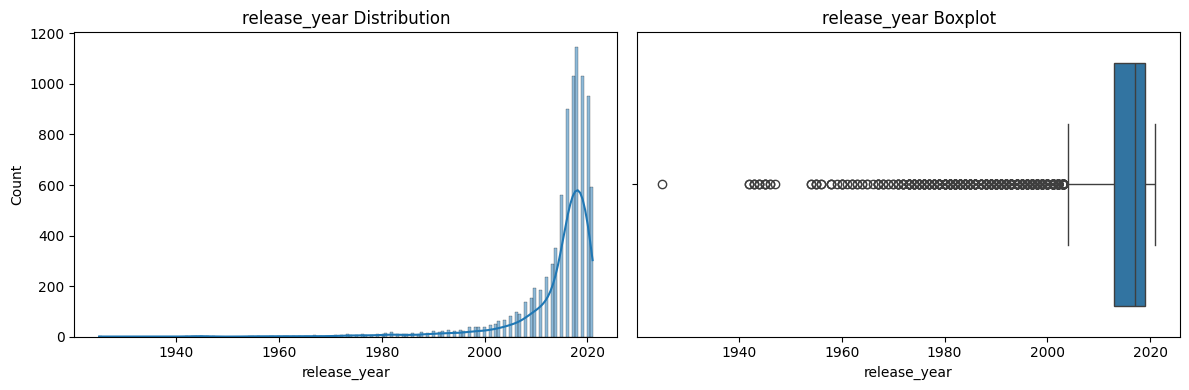

count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64
Skewness: -3.4465650403316013


In [65]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['release_year'], kde=True)
plt.title('release_year Distribution')
plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean['release_year'])
plt.title('release_year Boxplot')
plt.tight_layout()
plt.show()
print(df_clean['release_year'].describe())
print("Skewness:", df_clean['release_year'].skew())

## A4.2 Content type

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      0.696
TV Show    0.304
Name: proportion, dtype: float64


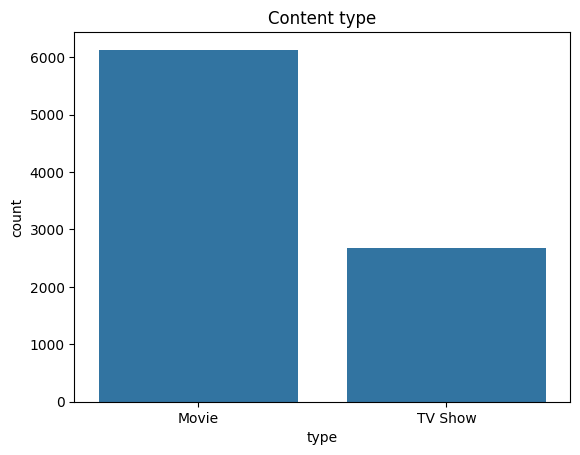

In [66]:
print(df_clean['type'].value_counts())
print(df_clean['type'].value_counts(normalize=True).round(3))
sns.countplot(data=df_clean, x='type')
plt.title('Content type')
plt.show()

## A4.3 Rating


rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
Unrated       83
G             41
Unknown        7
TV-Y7-FV       6
NC-17          3
Name: count, dtype: int64


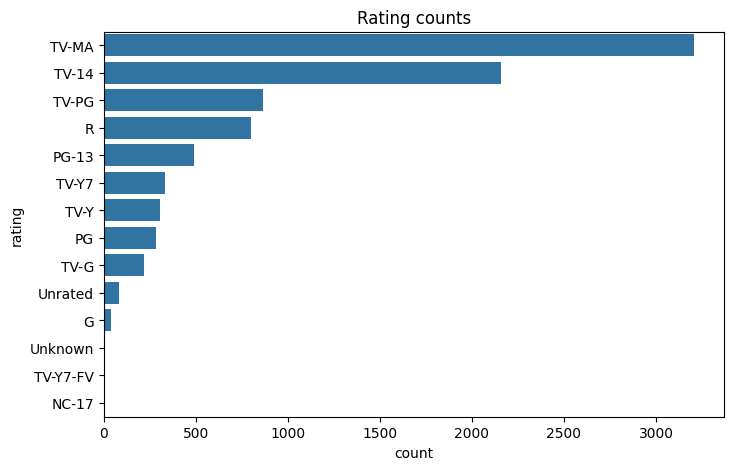

In [67]:
print(df_clean['rating'].value_counts())
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, y='rating', order=df_clean['rating'].value_counts().index)
plt.title('Rating counts')
plt.show()

## A4.4 Movie duration and TV-show seasons

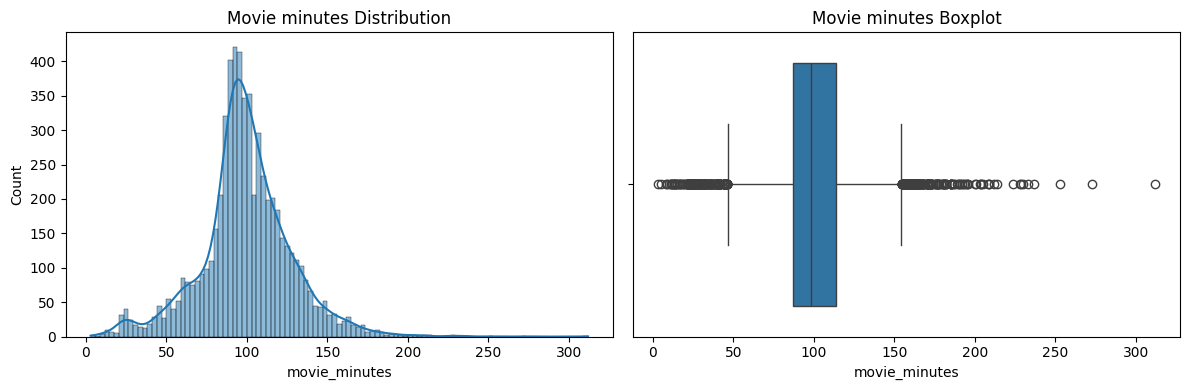

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_minutes, dtype: float64
Skewness: 0.20337565111840306


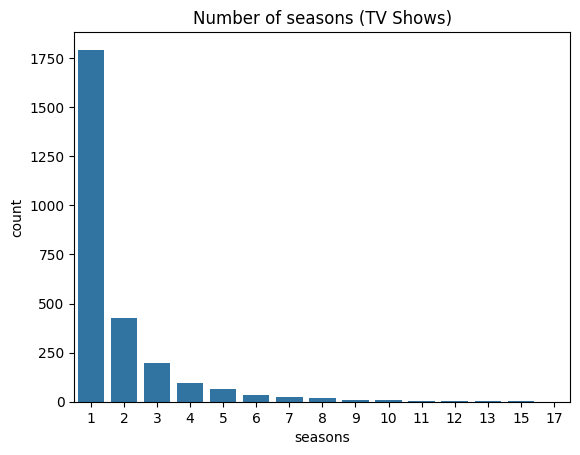

count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: seasons, dtype: float64
Skewness: 3.4185670153744647


In [68]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['movie_minutes'], kde=True)
plt.title('Movie minutes Distribution')
plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean['movie_minutes'])
plt.title('Movie minutes Boxplot')
plt.tight_layout()
plt.show()
print(df_clean['movie_minutes'].describe())
print("skewness:", df_clean['movie_minutes'].skew())

sns.countplot(x=df_clean['seasons'].dropna().astype(int))
plt.title('num of seasons (TV Shows)')
plt.show()

print(df_clean['seasons'].describe())
print("Skewness:", df_clean['seasons'].skew())

## A4.5 Number of countries and genres per title


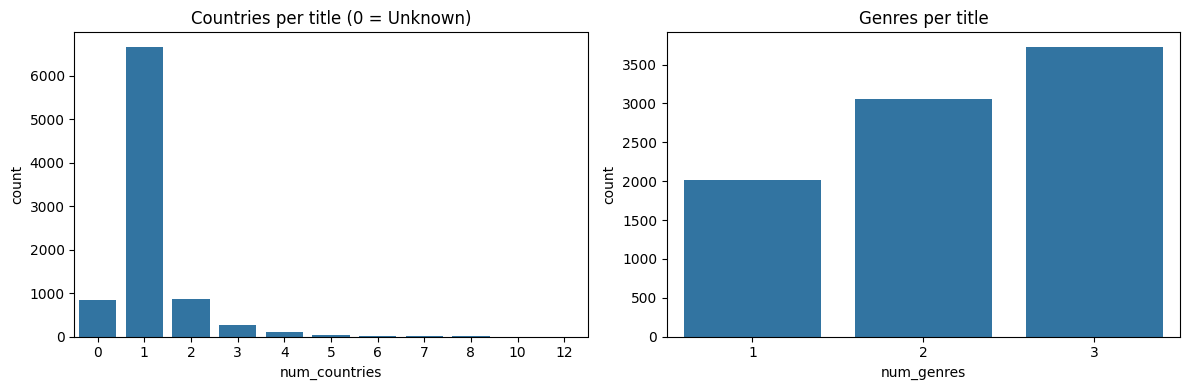

       num_countries   num_genres
count    8807.000000  8807.000000
mean        1.136823     2.194050
std         0.758338     0.784341
min         0.000000     1.000000
25%         1.000000     2.000000
50%         1.000000     2.000000
75%         1.000000     3.000000
max        12.000000     3.000000


In [69]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(x=df_clean['num_countries'])
plt.title('Countries per title (0 = Unknown)')
plt.subplot(1, 2, 2)
sns.countplot(x=df_clean['num_genres'])
plt.title('Genres per title')
plt.tight_layout()
plt.show()

print(df_clean[['num_countries', 'num_genres']].describe())

## A4.6 Multi-valued fields: top countries and genres


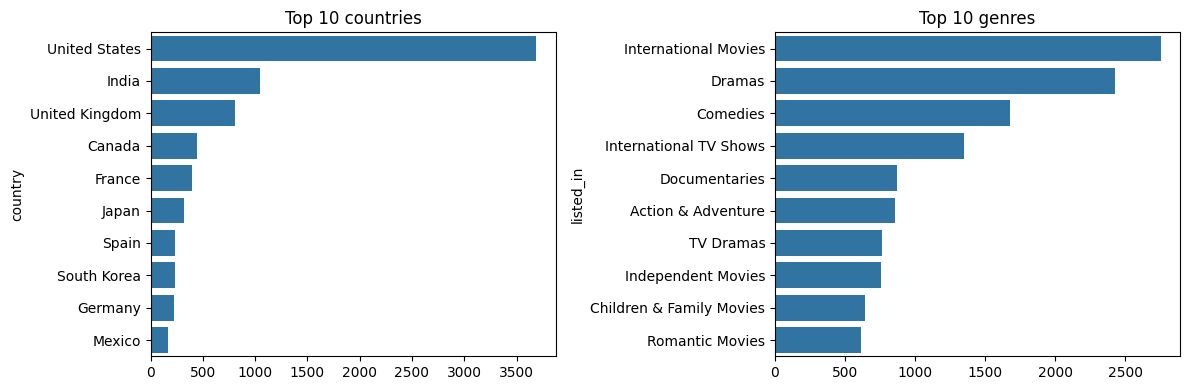

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [70]:
all_countries = df_clean['country'].str.split(',').explode().str.strip()
all_countries = all_countries[all_countries != 'Unknown']
top_countries = all_countries.value_counts().head(10)
all_genres = df_clean['listed_in'].str.split(',').explode().str.strip()
top_genres = all_genres.value_counts().head(10)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 10 countries')
plt.subplot(1, 2, 2)
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title('Top 10 genres')
plt.tight_layout()
plt.show()

print(top_countries)
print(top_genres)

# A5. Bivariate EDA
## A5.1 Numerical vs Numerical: release year vs movie length

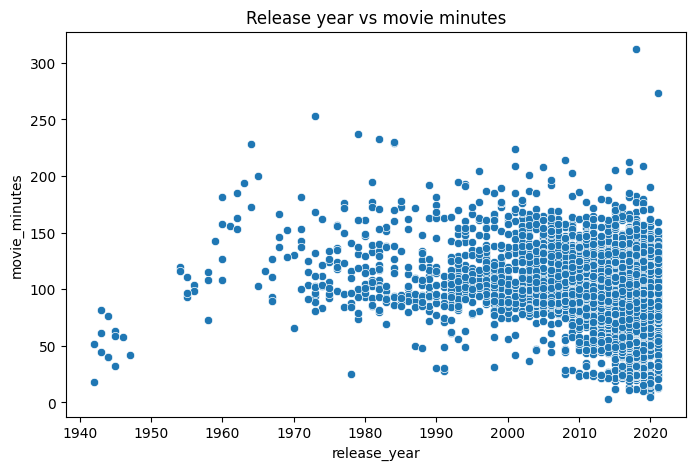

               release_year  movie_minutes
release_year       1.000000      -0.206305
movie_minutes     -0.206305       1.000000


In [71]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='release_year', y='movie_minutes')
plt.title('Release year vs movie minutes')
plt.show()
print(df_clean[['release_year', 'movie_minutes']].corr())

## A5.2 Numerical vs Categorical: movie length by rating group


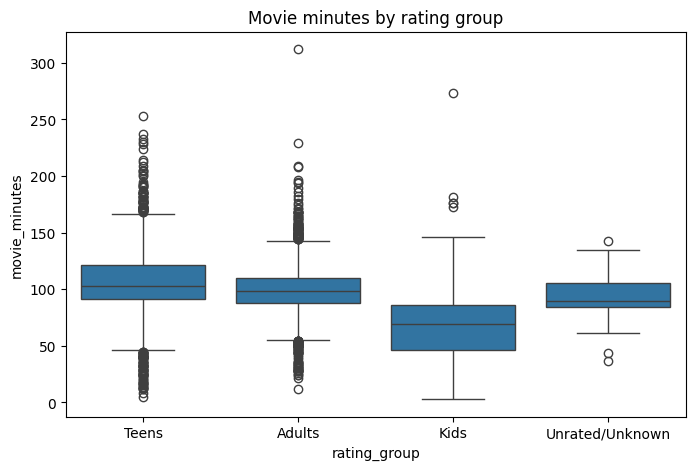

                  count        mean        std   min   25%    50%    75%  \
rating_group                                                               
Adults           2862.0   98.936408  23.164235  12.0  88.0   98.0  110.0   
Kids              442.0   66.963801  30.808582   3.0  46.0   69.5   86.0   
Teens            2744.0  105.646501  29.254058   5.0  91.0  103.0  121.0   
Unrated/Unknown    83.0   93.795181  18.953576  37.0  84.0   90.0  105.5   

                   max  
rating_group            
Adults           312.0  
Kids             273.0  
Teens            253.0  
Unrated/Unknown  143.0  


In [72]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='rating_group', y='movie_minutes')
plt.title('Movie minutes by rating group')
plt.show()
print(df_clean.groupby('rating_group')['movie_minutes'].describe())

## A5.3 Categorical vs Categorical: type vs rating group


rating_group  Adults   Kids  Teens  Unrated/Unknown
type                                               
Movie          0.467  0.072  0.448            0.014
TV Show        0.429  0.174  0.395            0.003


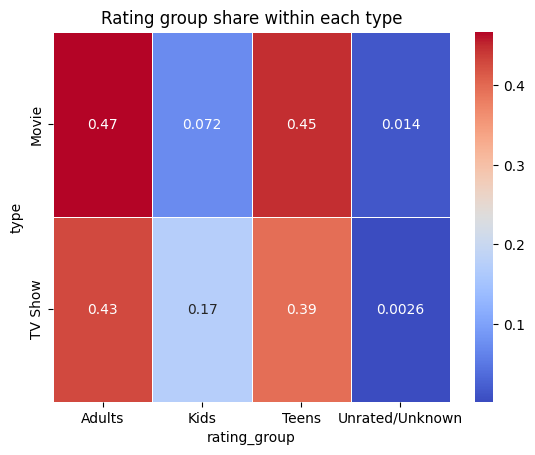

In [73]:
type_rating = pd.crosstab(df_clean['type'], df_clean['rating_group'], normalize='index')
print(type_rating.round(3))
sns.heatmap(type_rating, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Rating group share within each type')
plt.show()

# A6. Multivariate EDA
## A6.1 Correlation matrix of numerical variables

               release_year  year_added  gap_years  movie_minutes  seasons  \
release_year           1.00        0.11      -0.98          -0.21    -0.09   
year_added             0.11        1.00       0.07           0.13     0.04   
gap_years             -0.98        0.07       1.00           0.22     0.10   
movie_minutes         -0.21        0.13       0.22           1.00      NaN   
seasons               -0.09        0.04       0.10            NaN     1.00   
num_countries         -0.07       -0.07       0.06           0.09     0.12   
num_genres            -0.04        0.05       0.05           0.41    -0.08   
num_cast              -0.10        0.12       0.12           0.34     0.17   

               num_countries  num_genres  num_cast  
release_year           -0.07       -0.04     -0.10  
year_added             -0.07        0.05      0.12  
gap_years               0.06        0.05      0.12  
movie_minutes           0.09        0.41      0.34  
seasons                 0.12    

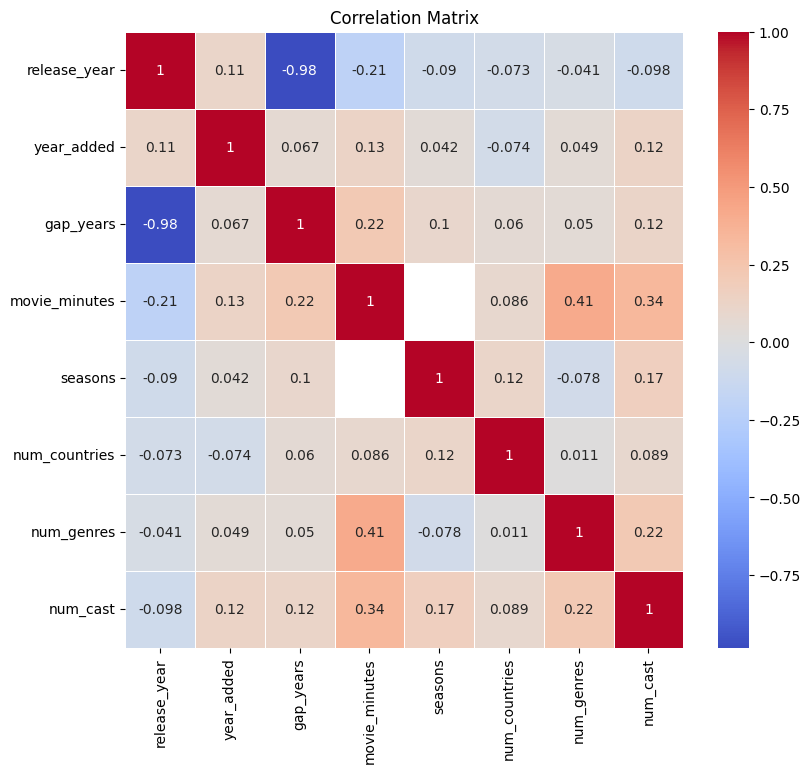

In [74]:
num_cols = ['release_year', 'year_added', 'gap_years', 'movie_minutes', 'seasons','num_countries', 'num_genres', 'num_cast']
correlation_matrix = df_clean[num_cols].corr()
print(correlation_matrix.round(2))
plt.figure(figsize=(9, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

## A6.2 Release year vs gap, split by type


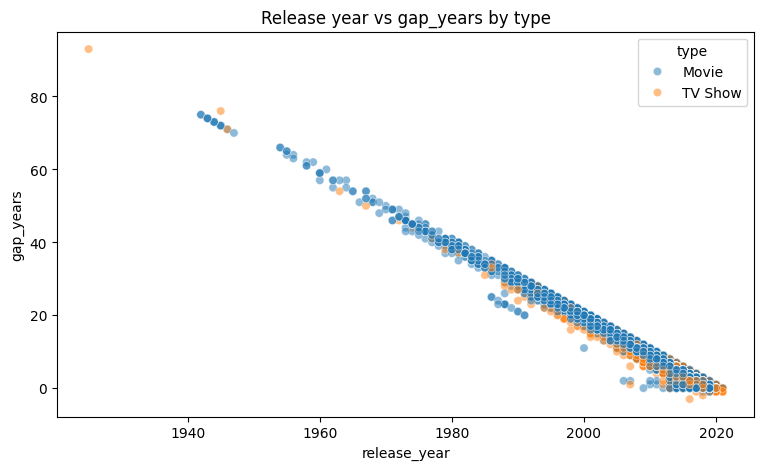

                      release_year  gap_years
type                                         
Movie   release_year      1.000000  -0.987085
        gap_years        -0.987085   1.000000
TV Show release_year      1.000000  -0.960767
        gap_years        -0.960767   1.000000


In [75]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x='release_year', y='gap_years', hue='type', alpha=0.5)
plt.title('Release year vs gap_years by type')
plt.show()
print(df_clean.groupby('type')[['release_year', 'gap_years']].corr())

# A7. Netflix-Specific Analytical Questions
## Q1. How has the mix of Movies and TV Shows changed over time?

type        Movie  TV Show
year_added                
2008.0      0.500    0.500
2009.0      1.000    0.000
2010.0      1.000    0.000
2011.0      1.000    0.000
2012.0      1.000    0.000
2013.0      0.545    0.455
2014.0      0.792    0.208
2015.0      0.683    0.317
2016.0      0.590    0.410
2017.0      0.706    0.294
2018.0      0.750    0.250
2019.0      0.706    0.294
2020.0      0.683    0.317
2021.0      0.663    0.337


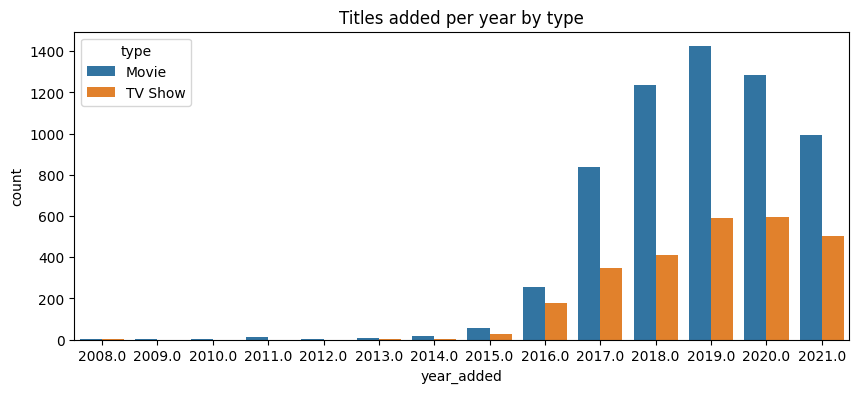

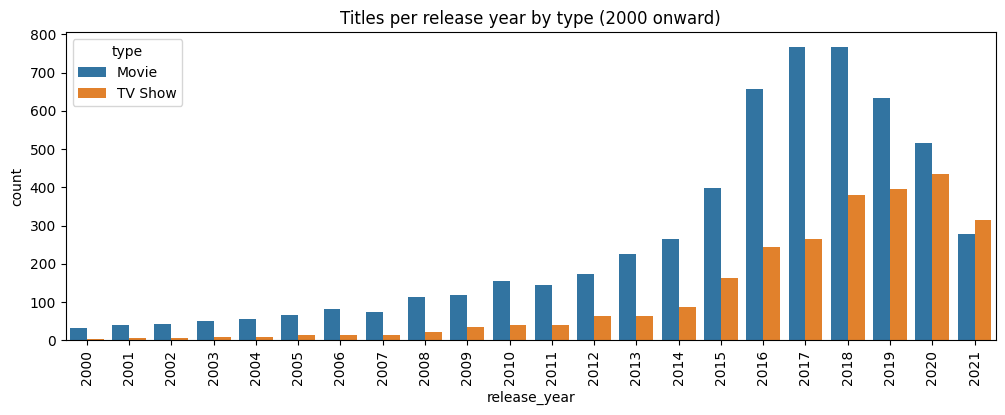

type
Movie      0.714
TV Show    0.286
Name: proportion, dtype: float64
type
Movie      0.686
TV Show    0.314
Name: proportion, dtype: float64


In [76]:
# by year added
print(pd.crosstab(df_clean['year_added'], df_clean['type'], normalize='index').round(3))

plt.figure(figsize=(10, 4))
sns.countplot(data=df_clean, x='year_added', hue='type')
plt.title('Titles added per year by type')
plt.show()

# by release year (2000 onward)
recent = df_clean[df_clean['release_year'] >= 2000]
plt.figure(figsize=(12, 4))
sns.countplot(data=recent, x='release_year', hue='type')
plt.xticks(rotation=90)
plt.title('Titles per release year by type (2000 onward)')
plt.show()

# tv show share before and after 2018
print(df_clean[df_clean['year_added'] <= 2018]['type'].value_counts(normalize=True).round(3))
print(df_clean[df_clean['year_added'] > 2018]['type'].value_counts(normalize=True).round(3))



 TV-show share was 28.6% among titles added up to 2018 and 31.4% after 2018. Counts added per year peak in 2019-2020 (about 1,900 to 2,000 titles per year) and fall in 2021, which only covers part of the year. Years before 2013 have only a handful of titles, so their shares (0% or 100%) are not reliable. By release year, titles are mostly from 2010 onward. **Interpretation:** the TV-show share rose modestly (about 3 percentage points) in later additions, but Movies stayed the majority. The data cannot say why.

## Q2. How does the gap between release year and date added vary?

count    8797.000000
mean        4.688417
std         8.786998
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: gap_years, dtype: float64
Added in release year (gap 0): 0.368
Gap of more than 5 years: 0.241


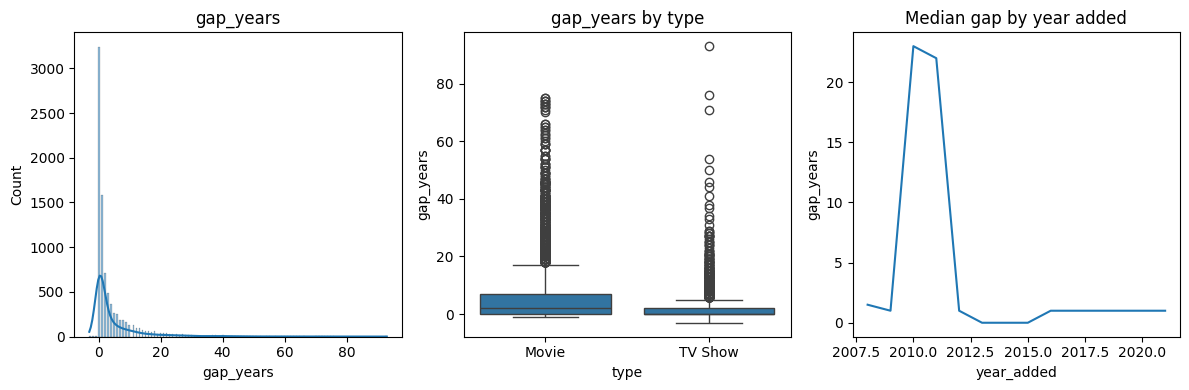

In [77]:
print(df_clean['gap_years'].describe())
print("Added in release year (gap 0):", (df_clean['gap_years'] == 0).mean().round(3))
print("Gap of more than 5 years:", (df_clean['gap_years'] > 5).mean().round(3))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.histplot(df_clean['gap_years'], kde=True)
plt.title('gap_years')
plt.subplot(1, 3, 2)
sns.boxplot(data=df_clean, x='type', y='gap_years')
plt.title('gap_years by type')
plt.subplot(1, 3, 3)
sns.lineplot(data=df_clean.groupby('year_added')['gap_years'].median())
plt.title('Median gap by year added')
plt.tight_layout()
plt.show()

**Observation:** median gap = 1 year, mean 4.7, max 93; 36.8% of titles were added in their release year and 24.1% had a gap of more than 5 years. The distribution is strongly right-skewed (mean much larger than median). The largest gap is *Pioneers: First Women Filmmakers* (1925, added 2018). Movies have a median gap of 2 years, TV Shows 0. **Interpretation:** a large gap means older titles were licensed / back-catalogue, a gap near 0 means fresh content; the median gap by year shows whether the catalogue moved from old to new content.

## Q3. Prominent countries and genres


listed_in       Action & Adventure  Children & Family Movies  Comedies  \
country                                                                  
Canada                        0.08                      0.15      0.18   
France                        0.05                      0.03      0.07   
India                         0.06                      0.01      0.13   
United Kingdom                0.08                      0.05      0.09   
United States                 0.10                      0.10      0.17   

listed_in       Documentaries  Dramas  Independent Movies  \
country                                                     
Canada                   0.08    0.16                0.08   
France                   0.06    0.24                0.11   
India                    0.01    0.27                0.07   
United Kingdom           0.13    0.20                0.07   
United States            0.13    0.21                0.10   

listed_in       International Movies  International T

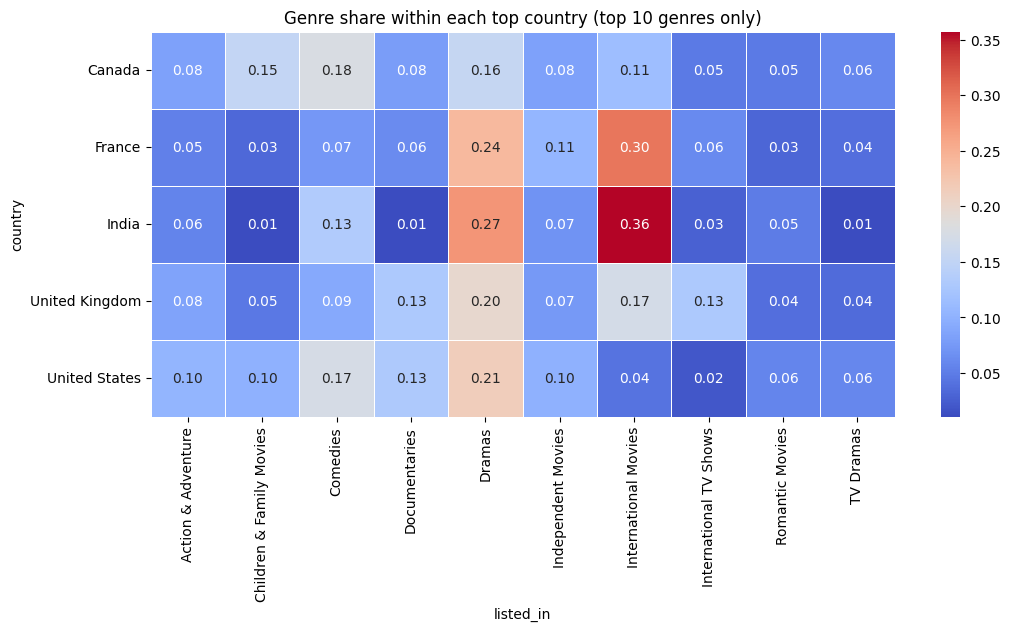

In [78]:
cg = df_clean[['country', 'listed_in']].copy()
cg['country'] = cg['country'].str.split(',')
cg = cg.explode('country').reset_index(drop=True)
cg['country'] = cg['country'].str.strip()
cg['listed_in'] = cg['listed_in'].str.split(',')
cg = cg.explode('listed_in').reset_index(drop=True)
cg['listed_in'] = cg['listed_in'].str.strip()

top5_countries = top_countries.head(5).index
cg = cg[cg['country'].isin(top5_countries) & cg['listed_in'].isin(top_genres.index)]

country_genre = pd.crosstab(cg['country'], cg['listed_in'], normalize='index')
print(country_genre.round(2))

plt.figure(figsize=(12, 5))
sns.heatmap(country_genre, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Genre share within each top country (top 10 genres only)')
plt.show()

India is dominated by International Movies (36%) and Dramas (27%); France is similar (30% and 24%); the US is spread across Dramas (21%), Comedies (17%) and Documentaries (13%) with only 4% International Movies; the UK has the highest share of International TV Shows (13%) and Documentaries (13%). the genre profiles clearly differ by country. "International Movies" is by definition non-US content, so that label partly describes the country. Shares are computed among the top-10 genres only.

## Q4. Maturity ratings: by type and over time

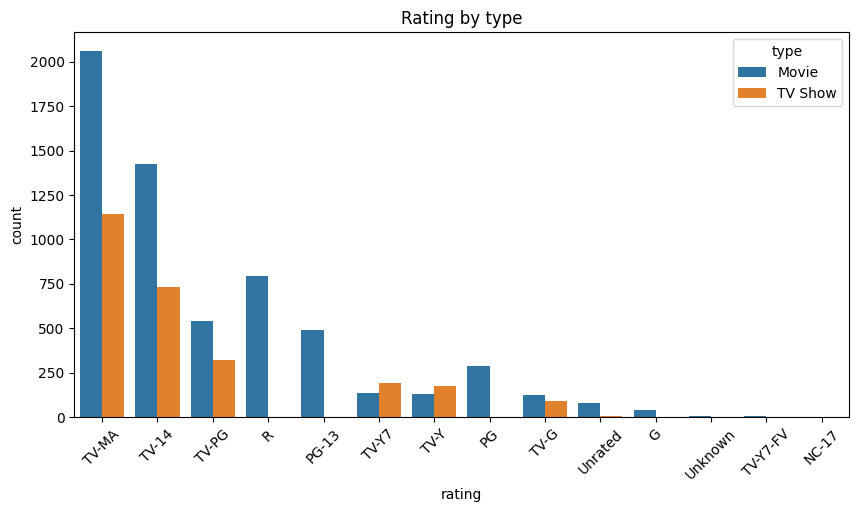

rating_group  Adults  Kids  Teens  Unrated/Unknown
year_added                                        
2008.0          1.00  0.00   0.00             0.00
2009.0          1.00  0.00   0.00             0.00
2010.0          0.00  0.00   0.00             1.00
2011.0          0.23  0.00   0.77             0.00
2012.0          0.33  0.00   0.67             0.00
2013.0          0.27  0.09   0.27             0.36
2014.0          0.50  0.12   0.38             0.00
2015.0          0.39  0.23   0.32             0.06
2016.0          0.41  0.15   0.37             0.07
2017.0          0.43  0.09   0.45             0.02
2018.0          0.47  0.08   0.44             0.01
2019.0          0.47  0.08   0.45             0.00
2020.0          0.46  0.12   0.42             0.00
2021.0          0.45  0.13   0.42             0.00


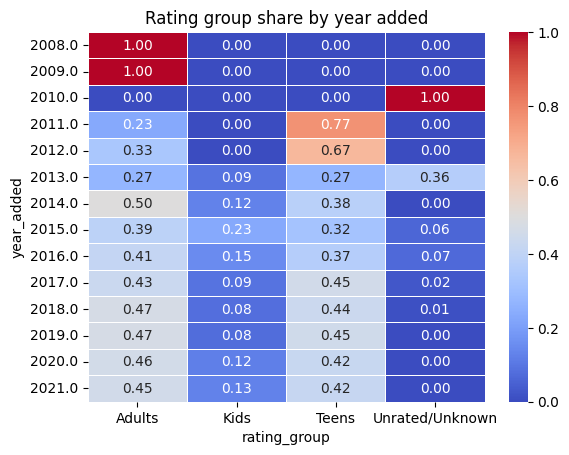

In [79]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_clean, x='rating', hue='type', order=df_clean['rating'].value_counts().index)
plt.xticks(rotation=45)
plt.title('Rating by type')
plt.show()
rating_year = pd.crosstab(df_clean['year_added'], df_clean['rating_group'], normalize='index')
print(rating_year.round(2))

sns.heatmap(rating_year, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Rating group share by year added')
plt.show()

**Observation:** TV-MA and TV-14 dominate for both types. TV-MA is 33.6% of Movies but 42.8% of TV Shows. Over time, the Adults share stays between 43% and 47% from 2017 to 2021, Teens between 42% and 45%, and Kids between 8% and 13%. **Interpretation:** ratings differ a little by type (TV Shows skew to TV-MA and have more Kids content) but the mix has been quite stable in recent years. Earlier years have too few titles to judge.

## Q5. Movie durations and TV-show seasons: unusual cases

In [80]:
print(df_clean[['title', 'movie_minutes']].sort_values('movie_minutes').head())
print(df_clean[['title', 'movie_minutes']].sort_values('movie_minutes').dropna().tail())
print()
print(df_clean['seasons'].value_counts().sort_index())
print(df_clean[df_clean['seasons'] >= 8][['title', 'seasons']])

                                                 title  movie_minutes
3777                                            Silent            3.0
2713                                       Sol Levante            5.0
1484                                  Cops and Robbers            8.0
1557                                            Canvas            9.0
3535  American Factory: A Conversation with the Obamas           10.0
                            title  movie_minutes
2484           Lock Your Girls In          233.0
2487               No Longer kids          237.0
2491       The School of Mischief          253.0
717   Headspace: Unwind Your Mind          273.0
4253   Black Mirror: Bandersnatch          312.0

seasons
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64
                                    title  seasons
8    

# A8. Insights and Handoff


In [81]:
print("Movie share overall:", (df_clean['type'] == 'Movie').mean().round(3))
print("Share of titles released 2015 or later:", (df_clean['release_year'] >= 2015).mean().round(3))
print("Share with Unknown director:", (df_clean['director'] == 'Unknown').mean().round(3))
print("Share with Unknown country:", (df_clean['country'] == 'Unknown').mean().round(3))
print("Median movie minutes:", df_clean['movie_minutes'].median())
print("Median gap years:", df_clean['gap_years'].median())

Movie share overall: 0.696
Share of titles released 2015 or later: 0.706
Share with Unknown director: 0.299
Share with Unknown country: 0.094
Median movie minutes: 98.0
Median gap years: 1.0


# PART B - SUPERMARKET SALES EDA

In [82]:
sm = pd.read_csv('supermarket_Sales.csv')

In [83]:
sm.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [84]:
sm.tail()
sm.shape
sm.info()
sm.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Invoice ID                      1000 non-null   object 
 1   Branch                          1000 non-null   object 
 2   City                            1000 non-null   object 
 3   Customer type                   1000 non-null   object 
 4   Gender                          1000 non-null   object 
 5   Product line                    1000 non-null   object 
 6   Unit price                      1000 non-null   float64
 7   Quantity                        1000 non-null   int64  
 8   Tax 5%                          1000 non-null   float64
 9   Total                           1000 non-null   float64
 10  Date                            1000 non-null   object 
 11  Time                            1000 non-null   object 
 12  Payment                         100

,Unit price,Quantity,Tax 5%,Total,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


The file has 1,000 rows and 17 columns, same as the description. Date and Time are read as text, Quantity is an integer and the other numbers are floats.

one row represents: one sale (invoice) of one product line to one customer at one branch.


# B2. Data Quality Assessment



In [107]:
# B2.1 missing values
print("Missing values in each column:")
print(sm.isnull().sum())

# B2.2 duplicate records
print("Full-row duplicates:", sm.duplicated().sum())
print("Duplicate Invoice ID:", sm['Invoice ID'].duplicated().sum())
print("Invoice ID lengths:", sm['Invoice ID'].str.len().unique())

# B2.3 incorrect data types
sm.dtypes
sm[['Date', 'Time']].head()

for col in ['Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Payment']:
    print(sm[col].value_counts())
    print()

pd.crosstab(sm['Branch'], sm['City'])


# B2.5
temp_date = pd.to_datetime(sm['Date'], format='%m/%d/%Y')
temp_hour = pd.to_datetime(sm['Time'], format='%H:%M').dt.hour
print("First date:", temp_date.min(), " Last date:", temp_date.max(), " Different days:", temp_date.nunique())
print("Earliest hour:", temp_hour.min(), " Latest hour:", temp_hour.max())
print("Rating min:", sm['Customer stratification rating'].min(), " max:", sm['Customer stratification rating'].max())
print("Ratings outside 0 to 10:", ((sm['Customer stratification rating'] < 0) | (sm['Customer stratification rating'] > 10)).sum())
print("Unit price x Quantity vs Cost of goods sold:", (sm['Unit price'] * sm['Quantity'] - sm['Cost of goods sold']).abs().max())
print("5% of Cost of goods sold vs Tax 5%:", (sm['Cost of goods sold'] * 0.05 - sm['Tax 5%']).abs().max())
print("Cost of goods sold + Tax vs Total:", (sm['Cost of goods sold'] + sm['Tax 5%'] - sm['Total']).abs().max())
print("Tax 5% equals Gross income in every row:", (sm['Tax 5%'] == sm['Gross income']).all())
print("Gross margin percentage values:", sm['Gross margin percentage'].unique())

# B2.6 Outliers
for col in ['Unit price', 'Quantity', 'Total', 'Customer stratification rating']:
    Q1 = sm[col].quantile(0.25)
    Q3 = sm[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR
    outliers = sm[(sm[col] < lower_bound) | (sm[col] > upper_bound)]
    print(col, "-> Lower:", lower_bound, "Upper:", upper_bound, "Outliers:", len(outliers))

Missing values in each column:
Invoice ID                        0
Branch                            0
City                              0
Customer type                     0
Gender                            0
Product line                      0
Unit price                        0
Quantity                          0
Tax 5%                            0
Total                             0
Date                              0
Time                              0
Payment                           0
Cost of goods sold                0
Gross margin percentage           0
Gross income                      0
Customer stratification rating    0
dtype: int64
Full-row duplicates: 0
Duplicate Invoice ID: 0
Invoice ID lengths: [11]
Branch
A    340
B    332
C    328
Name: count, dtype: int64

City
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64

Customer type
Member    501
Normal    499
Name: count, dtype: int64

Gender
Female    501
Male      499
Name: count, dtype: int6

# B3. Data Cleaning



In [104]:
pd.set_option('display.max_colwidth', None)

sm_decision_log = pd.DataFrame({
    'Problem': [
        "Missing values",
        "Duplicates",
        "Extra spaces in text columns",
        "Date and Time are text",
        "Branch and City match one to one",
        "Money columns are worked out from each other",
        "Gross margin percentage is the same in every row",
        "9 high Total values"],
    'How I found it': [
        "isnull().sum()",
        "duplicated() and Invoice ID check",
        "value_counts in B2.4",
        "dtypes",
        "crosstab",
        "recomputed them in B2.5",
        "unique()",
        "IQR rule"],
    'What I did': [
        "None found, nothing to fix",
        "None found, nothing removed",
        "Stripped them anyway as a safety step",
        "Converted Date to a date, took hour from Time",
        "Kept both",
        "Kept all of them",
        "Kept in the file, not used in the analysis",
        "Kept them"],
    'Why': [
        "Every column has 0 missing values",
        "Nothing to remove",
        "None were seen, so nothing changes",
        "Needed for month, weekday and hour",
        "They are the same information, so one is redundant (flagged for Assignment 3)",
        "They are correct, and I do not want to change the data given",
        "It has no variation",
        "Real big purchases (Quantity 10, unit price about 95 to 99), not mistakes"]
})
sm_decision_log

,Problem,How I found it,What I did,Why
0,Missing values,isnull().sum(),"None found, nothing to fix",Every column has 0 missing values
1,Duplicates,duplicated() and Invoice ID check,"None found, nothing removed",Nothing to remove
2,Extra spaces in text columns,value_counts in B2.4,Stripped them anyway as a safety step,"None were seen, so nothing changes"
3,Date and Time are text,dtypes,"Converted Date to a date, took hour from Time","Needed for month, weekday and hour"
4,Branch and City match one to one,crosstab,Kept both,"They are the same information, so one is redundant (flagged for Assignment 3)"
5,Money columns are worked out from each other,recomputed them in B2.5,Kept all of them,"They are correct, and I do not want to change the data given"
6,Gross margin percentage is the same in every row,unique(),"Kept in the file, not used in the analysis",It has no variation
7,9 high Total values,IQR rule,Kept them,"Real big purchases (Quantity 10, unit price about 95 to 99), not mistakes"


In [86]:
sm_clean = sm.copy()
text_columns = ["Invoice ID", "Branch", "City", "Customer type", "Gender", "Product line", "Date", "Time", "Payment"]

for col in text_columns:
    sm_clean[col] = sm_clean[col].str.strip()

sm_clean['Date'] = pd.to_datetime(sm_clean['Date'], format='%m/%d/%Y')

sm_clean['month'] = sm_clean['Date'].dt.month
sm_clean['day_of_week'] = sm_clean['Date'].dt.day_name()
sm_clean['is_weekend'] = (sm_clean['Date'].dt.dayofweek >= 5).astype(int)

sm_clean['hour'] = pd.to_datetime(sm_clean['Time'], format='%H:%M').dt.hour
sm_clean['time_period'] = pd.cut(sm_clean['hour'], bins=[9, 11, 15, 20], labels=['Morning (10-11)', 'Afternoon (12-15)', 'Evening (16-20)'])

print("Dataset shape:", sm_clean.shape)
print("Duplicate rows:", sm_clean.duplicated().sum())
print("Missing values:", sm_clean.isnull().sum().sum())
sm_clean[['Date', 'Time', 'month', 'day_of_week', 'is_weekend', 'hour', 'time_period']].head(10)

sm_clean.to_csv('23L_0993_A2_supermarket_cleaned.csv', index=False)

Dataset shape: (1000, 22)
Duplicate rows: 0
Missing values: 0


 no missing values, duplicates or wrong values were found, so no data values were changed.

# B4. Univariate EDA
## B4.1 Numerical variables

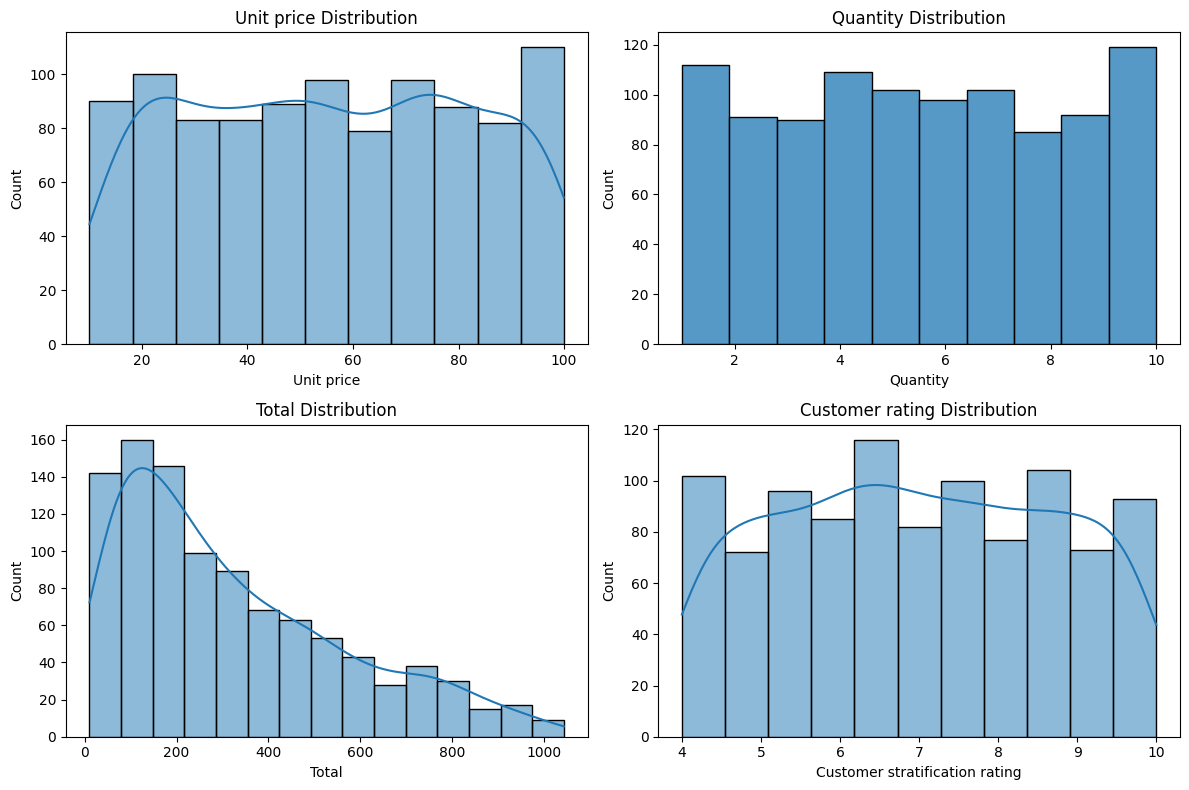

        Unit price     Quantity        Total  Customer stratification rating
count  1000.000000  1000.000000  1000.000000                      1000.00000
mean     55.672130     5.510000   322.966749                         6.97270
std      26.494628     2.923431   245.885335                         1.71858
min      10.080000     1.000000    10.678500                         4.00000
25%      32.875000     3.000000   124.422375                         5.50000
50%      55.230000     5.000000   253.848000                         7.00000
75%      77.935000     8.000000   471.350250                         8.50000
max      99.960000    10.000000  1042.650000                        10.00000

Skewness:
Unit price                        0.007077
Quantity                          0.012941
Total                             0.892570
Customer stratification rating    0.009010
dtype: float64


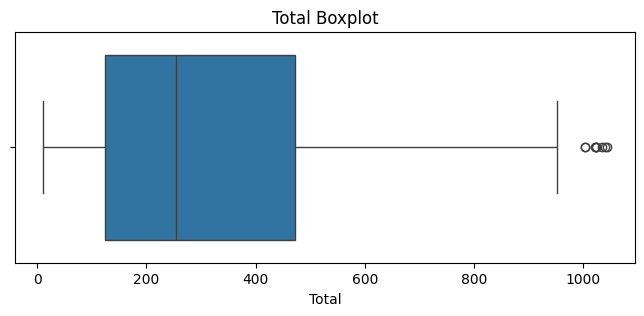

In [87]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
sns.histplot(sm_clean['Unit price'], kde=True)
plt.title('Unit price Distribution')
plt.subplot(2, 2, 2)
sns.histplot(sm_clean['Quantity'], bins=10)
plt.title('Quantity Distribution')
plt.subplot(2, 2, 3)
sns.histplot(sm_clean['Total'], kde=True)
plt.title('Total Distribution')
plt.subplot(2, 2, 4)
sns.histplot(sm_clean['Customer stratification rating'], kde=True)
plt.title('Customer rating Distribution')
plt.tight_layout()
plt.show()

num_cols = ['Unit price', 'Quantity', 'Total', 'Customer stratification rating']
print(sm_clean[num_cols].describe())
print()
print("Skewness:")
print(sm_clean[num_cols].skew())

# boxplot of Total to see the outliers found in B2.6
plt.figure(figsize=(8, 3))
sns.boxplot(x=sm_clean['Total'])
plt.title('Total Boxplot')
plt.show()

i observed that the total: mean 323.0, median 253.8, std 245.9, skewness 0.89 (skewed to the right, with 9 outliers above 991.74). Unit price (mean 55.7, std 26.5), Quantity (mean 5.5), and rating (mean 6.97, from 4 to 10) all have skewness close to 0.

Hence unit price, quantity and rating are spread fairly evenly between their minimum and maximum (their quartiles are almost evenly spaced). `Total` is skewed because it is price times quantity, so a few sales with both high give very large totals.

## B4.2 Categorical variables


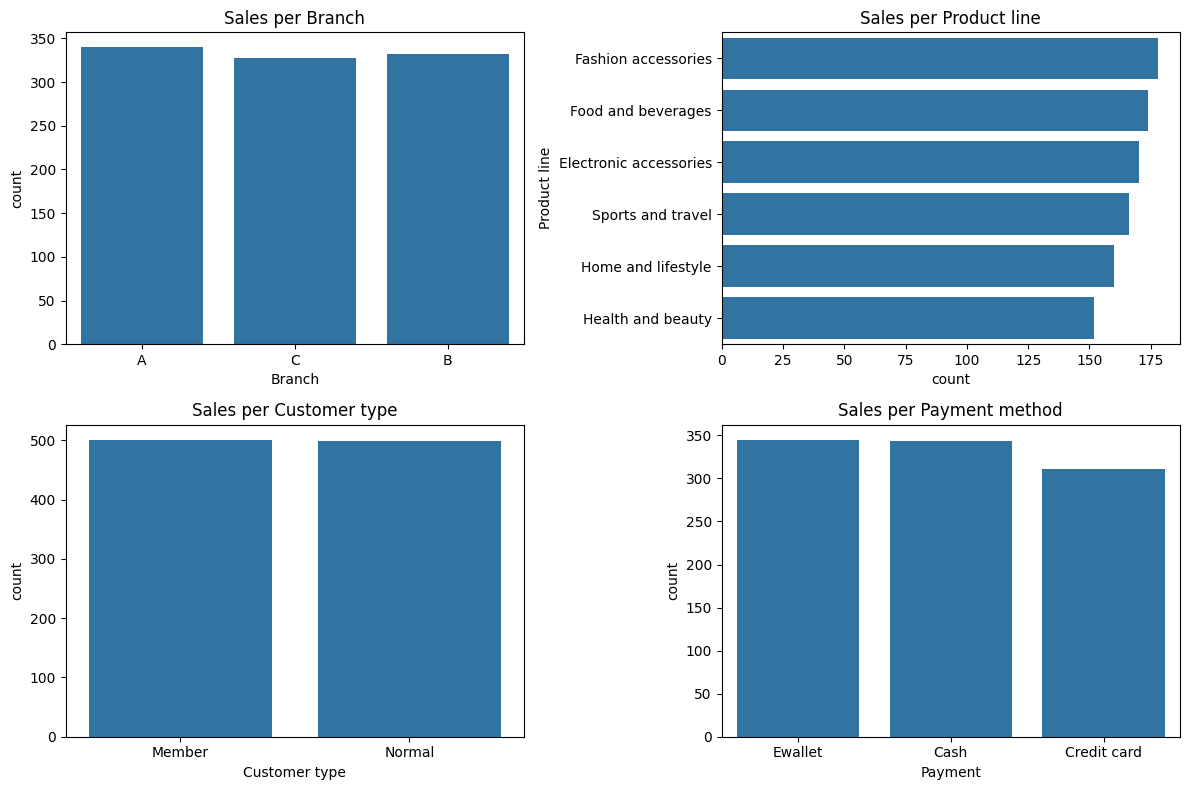

Product line
Fashion accessories       0.178
Food and beverages        0.174
Electronic accessories    0.170
Sports and travel         0.166
Home and lifestyle        0.160
Health and beauty         0.152
Name: proportion, dtype: float64


In [88]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
sns.countplot(data=sm_clean, x='Branch')
plt.title('Sales per Branch')
plt.subplot(2, 2, 2)
sns.countplot(data=sm_clean, y='Product line', order=sm_clean['Product line'].value_counts().index)
plt.title('Sales per Product line')
plt.subplot(2, 2, 3)
sns.countplot(data=sm_clean, x='Customer type')
plt.title('Sales per Customer type')
plt.subplot(2, 2, 4)
sns.countplot(data=sm_clean, x='Payment')
plt.title('Sales per Payment method')
plt.tight_layout()
plt.show()

print(sm_clean['Product line'].value_counts(normalize=True).round(3))

i observed that the groups are very balanced. Branch A 340, B 332, C 328. Customer type Member 501, Normal 499. Payment: Ewallet 345, Cash 344, Credit card 311. Product lines go from 152 sales (Health and beauty, 15.2%) to 178 (Fashion accessories, 17.8%).

 Hence, no category dominates, so simple counts do not separate the groups.

# B5. Bivariate EDA
## B5.1 Numerical vs Numerical: Quantity and Unit price vs Total


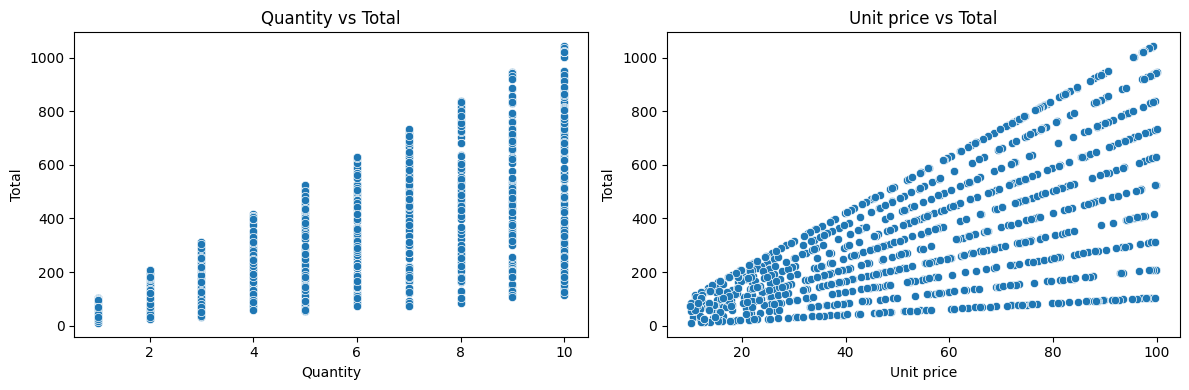

            Unit price  Quantity     Total
Unit price    1.000000  0.010778  0.633962
Quantity      0.010778  1.000000  0.705510
Total         0.633962  0.705510  1.000000


In [89]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.scatterplot(data=sm_clean, x='Quantity', y='Total')
plt.title('Quantity vs Total')
plt.subplot(1, 2, 2)
sns.scatterplot(data=sm_clean, x='Unit price', y='Total')
plt.title('Unit price vs Total')
plt.tight_layout()
plt.show()

print(sm_clean[['Unit price', 'Quantity', 'Total']].corr())

i observed that the correlation with total: Quantity 0.71, Unit price 0.63. Quantity and Unit price are not related to each other (0.01).

this is an artifact of how Total is defined (Total = Unit price x Quantity x 1.05), so the relationship is expected and is not a discovery. Both inputs drive the total, and they are independent of each other.

## B5.2 Numerical vs Categorical: Total by Product line

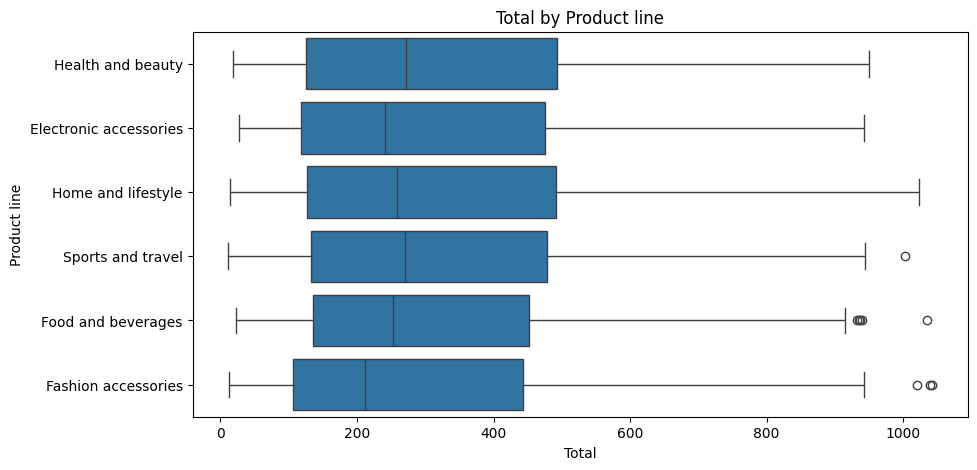

Product line
Fashion accessories       305.1
Electronic accessories    319.6
Food and beverages        322.7
Health and beauty         323.6
Sports and travel         332.1
Home and lifestyle        336.6
Name: Total, dtype: float64


In [90]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=sm_clean, x='Total', y='Product line')
plt.title('Total by Product line')
plt.show()

print(sm_clean.groupby('Product line')['Total'].mean().round(1).sort_values())

Observed tahat tge Members pay by credit card more (34.3% vs 27.9% for Normal). Normal customers use Ewallet (36.9% vs 32.1%) and Cash (35.3% vs 33.5%) a bit more.

the differences are only a few percentage points with about 500 customers in each group, so the link between customer type and payment is weak.

# B6. Multivariate EDA
## B6.1 Correlation matrix of numerical variables

                                Unit price  Quantity  Tax 5%  \
Unit price                            1.00      0.01    0.63   
Quantity                              0.01      1.00    0.71   
Tax 5%                                0.63      0.71    1.00   
Cost of goods sold                    0.63      0.71    1.00   
Gross income                          0.63      0.71    1.00   
Total                                 0.63      0.71    1.00   
Customer stratification rating       -0.01     -0.02   -0.04   
hour                                  0.01     -0.01   -0.00   

                                Cost of goods sold  Gross income  Total  \
Unit price                                    0.63          0.63   0.63   
Quantity                                      0.71          0.71   0.71   
Tax 5%                                        1.00          1.00   1.00   
Cost of goods sold                            1.00          1.00   1.00   
Gross income                                  1.

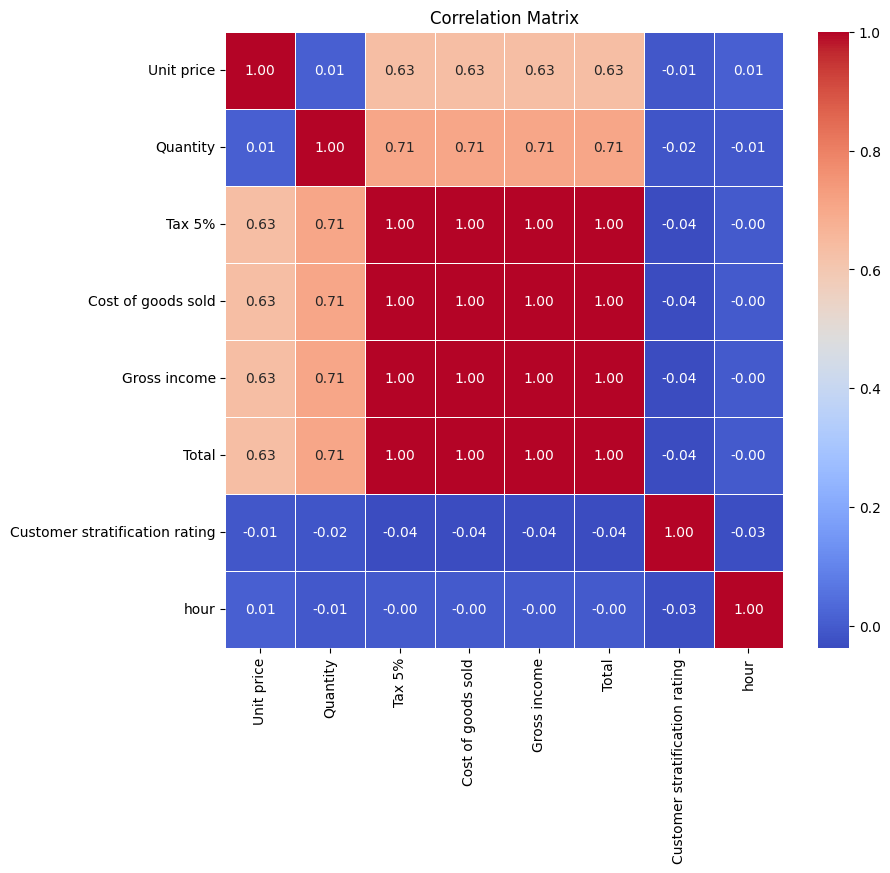

In [91]:
num_cols = ['Unit price', 'Quantity', 'Tax 5%', 'Cost of goods sold', 'Gross income', 'Total','Customer stratification rating', 'hour']
correlation_matrix = sm_clean[num_cols].corr()
print(correlation_matrix.round(2))

plt.figure(figsize=(9, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

Tax 5%, Cost of goods sold, Gross income and Total are correlated 1.00 with each other. Unit price (0.63) and Quantity (0.71) correlate with them. The rating (-0.04 with Total) and the hour (0.00) have almost no correlation with anything.

the four money columns are the same information (redundant), so one is enough. Rating and hour look unrelated to the money columns.

## B6.2 Total by Branch and Customer type

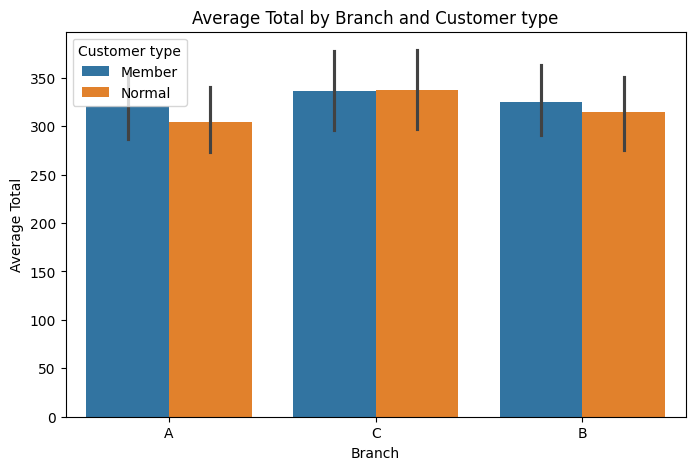

Branch  Customer type
A       Member           321.2
        Normal           303.8
B       Member           325.5
        Normal           314.3
C       Member           336.6
        Normal           337.7
Name: Total, dtype: float64


In [92]:
plt.figure(figsize=(8, 5))
sns.barplot(data=sm_clean, x='Branch', y='Total', hue='Customer type')
plt.title('Average Total by Branch and Customer type')
plt.ylabel('Average Total')
plt.show()

print(sm_clean.groupby(['Branch', 'Customer type'])['Total'].mean().round(1))

members spend more than Normal customers in Branch A (321.2 vs 303.8) and Branch B (325.5 vs 314.3), but in Branch C they are the same (336.6 vs 337.7).

the Member advantage is not the same in every branch, it disappears in C. Still, all these gaps (17, 11 and about 1) are small compared with the spread of Total (std about 245).

# B7. Supermarket Sales-Specific Analytical Questions

Product line
Food and beverages        56145.0
Sports and travel         55123.0
Electronic accessories    54338.0
Fashion accessories       54306.0
Home and lifestyle        53862.0
Health and beauty         49194.0
Name: Total, dtype: float64

Product line
Home and lifestyle        336.6
Sports and travel         332.1
Health and beauty         323.6
Food and beverages        322.7
Electronic accessories    319.6
Fashion accessories       305.1
Name: Total, dtype: float64

Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64


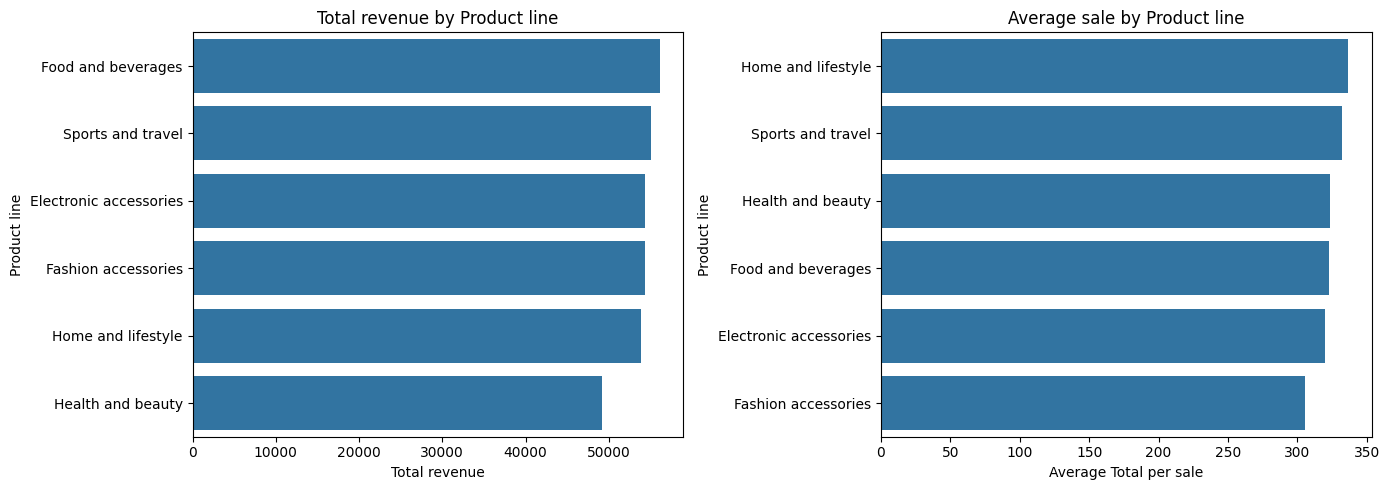

In [93]:
product_total = sm_clean.groupby('Product line')['Total'].sum().sort_values(ascending=False)
product_mean = sm_clean.groupby('Product line')['Total'].mean().sort_values(ascending=False)
print(product_total.round(0))
print()
print(product_mean.round(1))
print()
print(sm_clean['Product line'].value_counts())

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.barplot(x=product_total.values, y=product_total.index)
plt.title('Total revenue by Product line')
plt.xlabel('Total revenue')
plt.ylabel('Product line')
plt.subplot(1, 2, 2)
sns.barplot(x=product_mean.values, y=product_mean.index)
plt.title('Average sale by Product line')
plt.xlabel('Average Total per sale')
plt.ylabel('Product line')
plt.tight_layout()
plt.show()

Revenue ranking: Food and beverages 56,145, Sports and travel 55,123, Electronic accessories 54,338, Fashion accessories 54,306, Home and lifestyle 53,862, Health and beauty 49,194. By average sale the order changes: Home and lifestyle is first (336.6) and Fashion accessories is last (305.1). Food and beverages drops from 1st to 4th, and Fashion accessories has the most sales (178) but the lowest average.

revenue depends on how many sales there are and on the average sale. The top five lines are within about 4% of each other. Health and beauty is lowest mainly because it has the fewest sales (152).

## Q2

Branch
A    106200.0
B    106198.0
C    110569.0
Name: Total, dtype: float64

Average:
         Total  Quantity  Customer stratification rating
Branch                                                  
A       312.35      5.47                            7.03
B       319.87      5.48                            6.82
C       337.10      5.58                            7.07

Standard deviation inside each branch:
         Total  Quantity  Customer stratification rating
Branch                                                  
A       231.64      2.86                            1.73
B       242.45      2.90                            1.71
C       263.16      3.02                            1.70


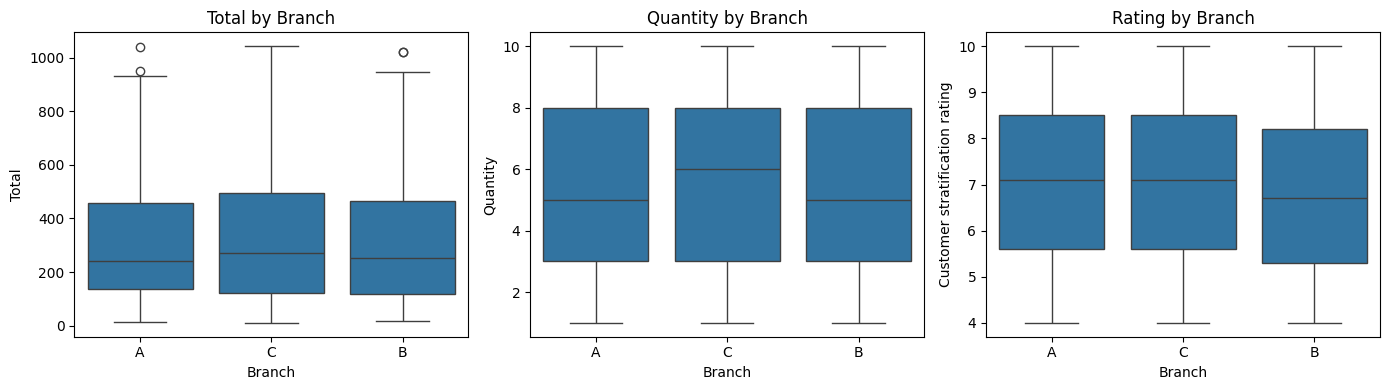

In [94]:
print(sm_clean.groupby('Branch')['Total'].sum().round(0))
print()
print("Average:")
print(sm_clean.groupby('Branch')[['Total', 'Quantity', 'Customer stratification rating']].mean().round(2))
print()
print("Standard deviation inside each branch:")
print(sm_clean.groupby('Branch')[['Total', 'Quantity', 'Customer stratification rating']].std().round(2))

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
sns.boxplot(data=sm_clean, x='Branch', y='Total')
plt.title('Total by Branch')
plt.subplot(1, 3, 2)
sns.boxplot(data=sm_clean, x='Branch', y='Quantity')
plt.title('Quantity by Branch')
plt.subplot(1, 3, 3)
sns.boxplot(data=sm_clean, x='Branch', y='Customer stratification rating')
plt.title('Rating by Branch')
plt.tight_layout()
plt.show()

Revenue: A 106,200, B 106,198, C 110,569. Average Total: A 312.3, B 319.9, C 337.1. Average quantity: 5.47, 5.48, 5.58. Average rating: A 7.03, B 6.82, C 7.07. Spread inside each branch: Total std 232 to 263, quantity std about 2.9, rating std about 1.7.

Branch C is a little higher in sales, but the gap between branches (up to 25 in Total, 0.25 in rating) is small compared with the spread inside each branch. The boxplots overlap almost completely, so the differences are small in practice. I did not run a statistical test.

## Q3

               count   mean    std   min    25%    50%    75%     max
Customer type                                                        
Member         501.0  327.8  248.0  10.7  118.3  266.0  485.6  1042.6
Normal         499.0  318.1  243.9  12.7  129.2  237.4  462.6  1039.3

             count   mean    std   min    25%    50%    75%     max
Payment                                                            
Cash         344.0  326.2  242.7  10.7  132.7  263.0  473.5  1003.6
Credit card  311.0  324.0  257.1  12.7  118.2  239.6  478.8  1042.6
Ewallet      345.0  318.8  239.3  13.4  122.5  253.7  469.4  1034.5


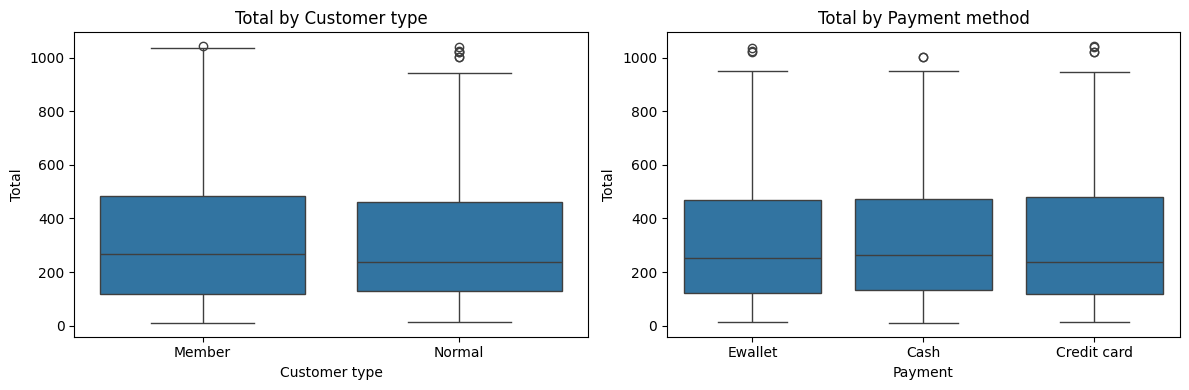

In [95]:
print(sm_clean.groupby('Customer type')['Total'].describe().round(1))
print()
print(sm_clean.groupby('Payment')['Total'].describe().round(1))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=sm_clean, x='Customer type', y='Total')
plt.title('Total by Customer type')
plt.subplot(1, 2, 2)
sns.boxplot(data=sm_clean, x='Payment', y='Total')
plt.title('Total by Payment method')
plt.tight_layout()
plt.show()

average Total: Member 327.8 vs Normal 318.1. By payment: Cash 326.2, Credit card 324.0, Ewallet 318.8. The standard deviation is about 240 to 257 in every group.

the differences (about 10 for customer type, about 7 for payment) are tiny compared with the spread, and the boxplots overlap. No clear spending difference.

## Q4. How do sales change by time of day and day of week?

hour
10    31421.0
11    30377.0
12    26066.0
13    34723.0
14    30828.0
15    31180.0
16    25226.0
17    24445.0
18    26030.0
19    39700.0
20    22970.0
Name: Total, dtype: float64

day_of_week
Friday       43926.0
Monday       37899.0
Saturday     56121.0
Sunday       44458.0
Thursday     45349.0
Tuesday      51482.0
Wednesday    43731.0
Name: Total, dtype: float64

day_of_week
Saturday     164
Tuesday      158
Wednesday    143
Friday       139
Thursday     138
Sunday       133
Monday       125
Name: count, dtype: int64

time_period
Morning (10-11)       61799.0
Afternoon (12-15)    122797.0
Evening (16-20)      138371.0
Name: Total, dtype: float64


/tmp/ipykernel_2479/3966129395.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(sm_clean.groupby('time_period')['Total'].sum().round(0))


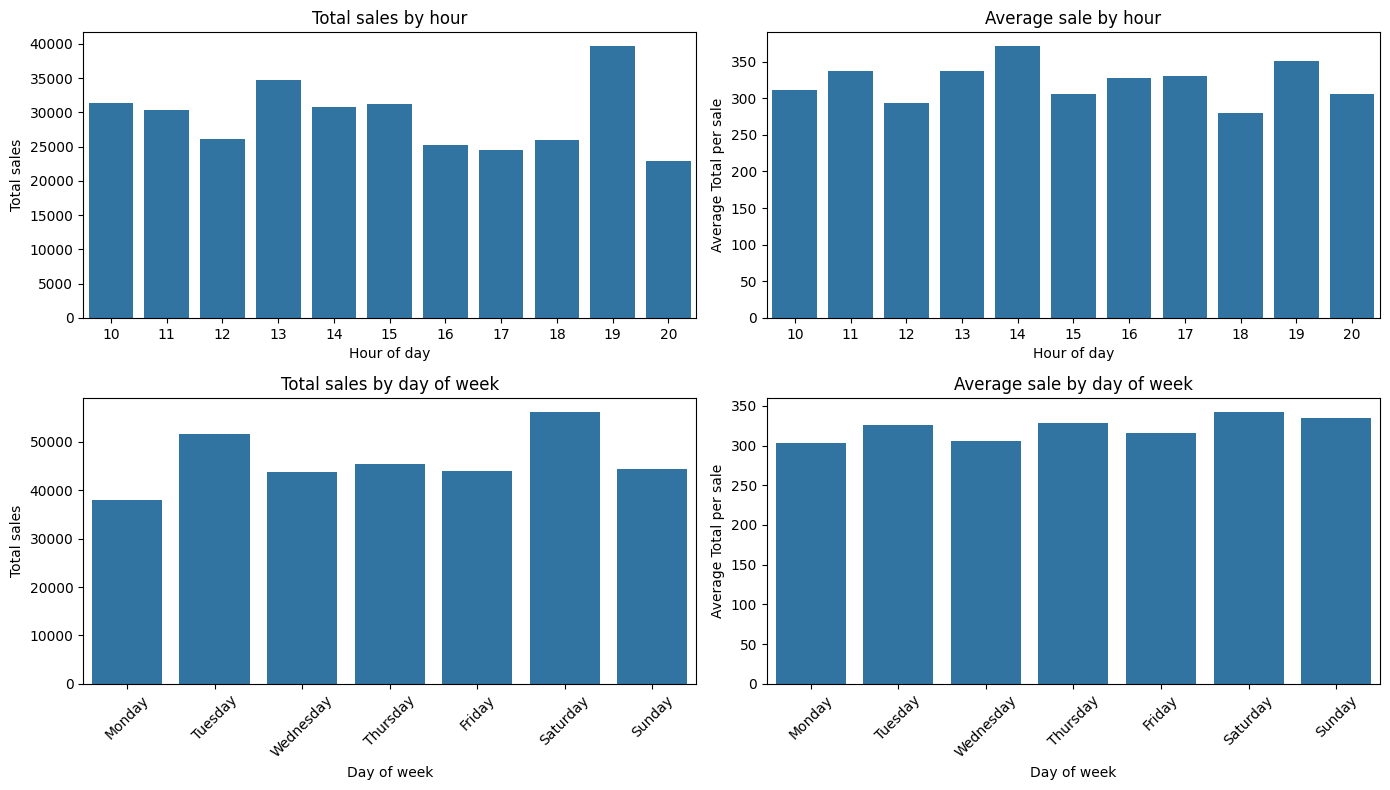

In [96]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

hour_total = sm_clean.groupby('hour')['Total'].sum()
hour_mean = sm_clean.groupby('hour')['Total'].mean()
day_total = sm_clean.groupby('day_of_week')['Total'].sum()
day_mean = sm_clean.groupby('day_of_week')['Total'].mean()

print(hour_total.round(0))
print()
print(day_total.round(0))
print()
print(sm_clean['day_of_week'].value_counts())
print()
print(sm_clean.groupby('time_period')['Total'].sum().round(0))

plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
sns.barplot(x=hour_total.index, y=hour_total.values)
plt.title('Total sales by hour')
plt.xlabel('Hour of day')
plt.ylabel('Total sales')
plt.subplot(2, 2, 2)
sns.barplot(x=hour_mean.index, y=hour_mean.values)
plt.title('Average sale by hour')
plt.xlabel('Hour of day')
plt.ylabel('Average Total per sale')
plt.subplot(2, 2, 3)
sns.barplot(x=day_total.index, y=day_total.values, order=day_order)
plt.title('Total sales by day of week')
plt.xlabel('Day of week')
plt.ylabel('Total sales')
plt.xticks(rotation=45)
plt.subplot(2, 2, 4)
sns.barplot(x=day_mean.index, y=day_mean.values, order=day_order)
plt.title('Average sale by day of week')
plt.xlabel('Day of week')
plt.ylabel('Average Total per sale')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q5. Is the customer rating related to price, quantity, product line or branch?

                                Customer stratification rating  Unit price  \
Customer stratification rating                           1.000      -0.009   
Unit price                                              -0.009       1.000   
Quantity                                                -0.016       0.011   
Total                                                   -0.036       0.634   

                                Quantity  Total  
Customer stratification rating    -0.016 -0.036  
Unit price                         0.011  0.634  
Quantity                           1.000  0.706  
Total                              0.706  1.000  

Product line
Electronic accessories    6.92
Fashion accessories       7.03
Food and beverages        7.11
Health and beauty         7.00
Home and lifestyle        6.84
Sports and travel         6.92
Name: Customer stratification rating, dtype: float64

Branch
A    7.03
B    6.82
C    7.07
Name: Customer stratification rating, dtype: float64


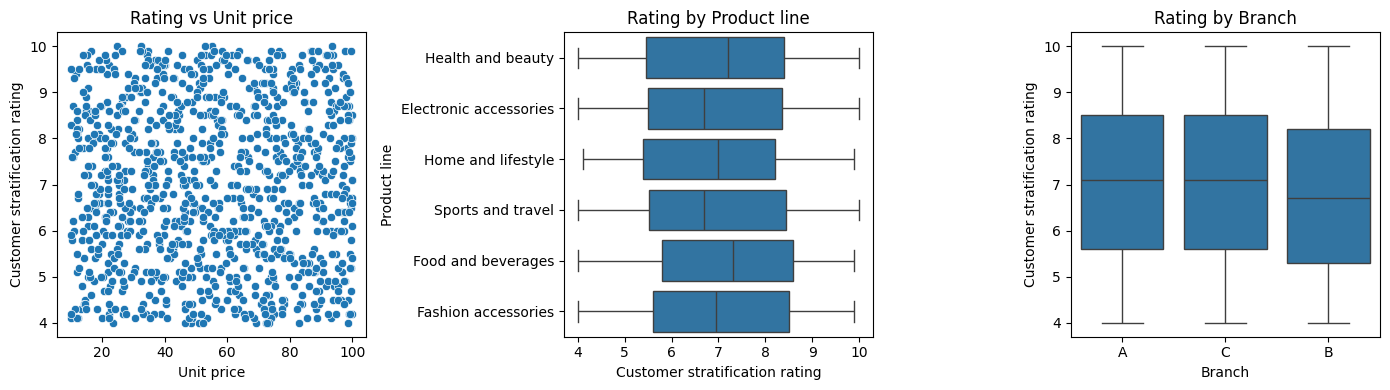

In [97]:
print(sm_clean[['Customer stratification rating', 'Unit price', 'Quantity', 'Total']].corr().round(3))
print()
print(sm_clean.groupby('Product line')['Customer stratification rating'].mean().round(2))
print()
print(sm_clean.groupby('Branch')['Customer stratification rating'].mean().round(2))

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
sns.scatterplot(data=sm_clean, x='Unit price', y='Customer stratification rating')
plt.title('Rating vs Unit price')
plt.subplot(1, 3, 2)
sns.boxplot(data=sm_clean, x='Customer stratification rating', y='Product line')
plt.title('Rating by Product line')
plt.subplot(1, 3, 3)
sns.boxplot(data=sm_clean, x='Branch', y='Customer stratification rating')
plt.title('Rating by Branch')
plt.tight_layout()
plt.show()

# B8. Insights

In [98]:
print("Total revenue:", sm_clean['Total'].sum().round(0))
print("Average sale:", sm_clean['Total'].mean().round(1))
print("Correlation of rating with Total:", sm_clean['Customer stratification rating'].corr(sm_clean['Total']).round(3))
print("Correlation of Quantity with Total:", sm_clean['Quantity'].corr(sm_clean['Total']).round(3))
print("Member vs Normal average sale:")
print(sm_clean.groupby('Customer type')['Total'].mean().round(1))

Total revenue: 322967.0
Average sale: 323.0
Correlation of rating with Total: -0.036
Correlation of Quantity with Total: 0.706
Member vs Normal average sale:
Customer type
Member    327.8
Normal    318.1
Name: Total, dtype: float64
